Abi Muthuraman KNN Classification

In [2]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, cross_val_score, GroupKFold, GroupShuffleSplit
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay

In [3]:
#loading and verifying the shared split
X_train = pd.read_csv("../data/training/X_train.csv")
X_test = pd.read_csv("../data/training/X_test.csv")
y_train = pd.read_csv("../data/training/y_train.csv")["is_carcinogenic"]
y_test = pd.read_csv("../data/training/y_test.csv")["is_carcinogenic"]

print("train rows:", len(X_train), "| test rows:", len(X_test), "| features:", X_train.shape[1])
print("share carcinogenic in train:", round(y_train.mean(), 3))
X_train.iloc[:3, :8]

train rows: 5892 | test rows: 1353 | features: 364
share carcinogenic in train: 0.411


,xpotime,xprtime,ndoses,log_max_dose,num_dose_groups,species_h,species_m,species_n
0,26,77,1,-2.853872,1,False,False,False
1,26,77,1,-2.853872,1,False,False,False
2,100,100,1,1.795880,1,False,True,False


In [4]:
#scaling the data; the 5 numeric columns are scaled. the rest have 0/1 (species, strain, sex, route, and tissue).
num_cols = ["xpotime", "xprtime", "ndoses", "log_max_dose", "num_dose_groups"]
scaler = StandardScaler()
X_train_s = X_train.copy()
X_test_s = X_test.copy()
X_train_s[num_cols] = scaler.fit_transform(X_train[num_cols])   
X_test_s[num_cols] = scaler.transform(X_test[num_cols])         
X_train_s[num_cols].describe().round(2).loc[["mean", "std"]]

,xpotime,xprtime,ndoses,log_max_dose,num_dose_groups
mean,-0.0,-0.0,0.0,0.0,0.0
std,1.0,1.0,1.0,1.0,1.0


In [5]:
#choose the number of neighbors to use for KNN
exp = pd.read_csv("../data/training/experiments.csv", keep_default_na=False)
train_chems, test_chems = train_test_split(exp["chemcode"].unique(), test_size=0.2, random_state=42)
chem_train = exp.loc[exp["chemcode"].isin(train_chems), "chemcode"].reset_index(drop=True)
assert len(chem_train) == len(X_train)

k_values = [5, 11, 21, 41, 81, 161]
cv_scores = []
for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    auc = cross_val_score(knn, X_train_s, y_train, groups=chem_train, cv=GroupKFold(n_splits=5), scoring="roc_auc").mean()
    cv_scores.append(auc)
    print(f"k = {k:3d}   cross-validated ROC-AUC = {auc:.3f}")

best_k = k_values[int(np.argmax(cv_scores))]
print("\nBest k:", best_k)

k =   5   cross-validated ROC-AUC = 0.791
k =  11   cross-validated ROC-AUC = 0.809
k =  21   cross-validated ROC-AUC = 0.820
k =  41   cross-validated ROC-AUC = 0.816
k =  81   cross-validated ROC-AUC = 0.814
k = 161   cross-validated ROC-AUC = 0.807

Best k: 21


In [6]:
#fit and evaluate the model on the test set
knn = KNeighborsClassifier(n_neighbors=best_k)
knn.fit(X_train_s, y_train)

pred = knn.predict(X_test_s)                  
proba = knn.predict_proba(X_test_s)[:, 1]
results = {
    "accuracy": accuracy_score(y_test, pred),
    "precision": precision_score(y_test, pred),
    "recall": recall_score(y_test, pred),
    "roc_auc": roc_auc_score(y_test, proba),
}
pd.Series(results).round(3)

accuracy     0.789
precision    0.836
recall       0.641
roc_auc      0.896
dtype: float64

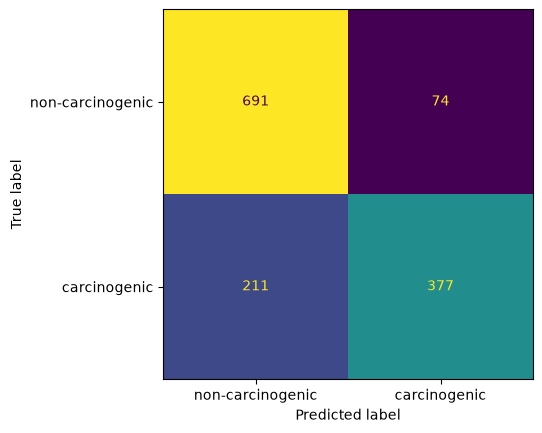

In [7]:
ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=["non-carcinogenic", "carcinogenic"]).plot(colorbar=False)

In [8]:
#model that predicts the most common class. KNN needs to be better than this to be useful.
baseline = DummyClassifier(strategy="most_frequent").fit(X_train_s, y_train)
base_pred = baseline.predict(X_test_s)
comparison = pd.DataFrame({
    "Baseline": {"accuracy": accuracy_score(y_test, base_pred), "precision": 0.0, "recall": 0.0, "roc_auc": 0.5},
    "KNN": results,
}).T.round(3)
comparison

,accuracy,precision,recall,roc_auc
Baseline,0.565,0.000,0.000,0.500
KNN,0.789,0.836,0.641,0.896


In [9]:
#seeing if tissue matters and if ndoses (since its a duplicate of num_dose_groups) can be dropped. 
def run_knn(cols):
    num = [c for c in num_cols if c in cols]
    Xtr, Xte = X_train[cols].copy(), X_test[cols].copy()
    sc = StandardScaler()
    Xtr[num] = sc.fit_transform(Xtr[num])
    Xte[num] = sc.transform(Xte[num])
    scores = [cross_val_score(KNeighborsClassifier(n_neighbors=k), Xtr, y_train, groups=chem_train,
                              cv=GroupKFold(n_splits=5), scoring="roc_auc").mean() for k in k_values]
    k = k_values[int(np.argmax(scores))]
    model = KNeighborsClassifier(n_neighbors=k).fit(Xtr, y_train)
    pred, proba = model.predict(Xte), model.predict_proba(Xte)[:, 1]
    return {"k": k, "accuracy": accuracy_score(y_test, pred), "precision": precision_score(y_test, pred),
            "recall": recall_score(y_test, pred), "roc_auc": roc_auc_score(y_test, proba)}

all_cols = list(X_train.columns)
tissue_cols = [c for c in all_cols if c.startswith("tissue_")]
variants = {
    "as shared (all features)": all_cols,
    "drop duplicate ndoses": [c for c in all_cols if c != "ndoses"],
    "no tissue": [c for c in all_cols if not c.startswith("tissue_")],
}
table = pd.DataFrame({name: run_knn(cols) for name, cols in variants.items()}).T
table.round(3)

,k,accuracy,precision,recall,roc_auc
as shared (all features),21.0,0.789,0.836,0.641,0.896
drop duplicate ndoses,21.0,0.789,0.840,0.634,0.894
no tissue,41.0,0.751,0.760,0.624,0.853


In [10]:
#how well the tissue colums do on their own
lr = LogisticRegression(max_iter=1000).fit(X_train[tissue_cols], y_train)
print("ROC-AUC using ONLY the tissue columns:", round(roc_auc_score(y_test, lr.predict_proba(X_test[tissue_cols])[:, 1]), 3))

ROC-AUC using ONLY the tissue columns: 0.837


In [11]:
#repeat he whole thing on 20 different random chemical grouped splits and average.
X_all = pd.concat([X_train, X_test], ignore_index=True)
y_all = pd.concat([y_train, y_test], ignore_index=True)
chem_test = exp.loc[~exp["chemcode"].isin(train_chems), "chemcode"].reset_index(drop=True)
chem_all = pd.concat([chem_train, chem_test], ignore_index=True)

stab = {name: [] for name in variants}
for seed in range(20):
    tr, te = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=seed).split(X_all, y_all, chem_all))
    for name, cols in variants.items():
        num = [c for c in num_cols if c in cols]
        Xtr, Xte = X_all.iloc[tr][cols].copy(), X_all.iloc[te][cols].copy()
        sc = StandardScaler()
        Xtr[num] = sc.fit_transform(Xtr[num])
        Xte[num] = sc.transform(Xte[num])
        model = KNeighborsClassifier(n_neighbors=int(table.loc[name, "k"])).fit(Xtr, y_all.iloc[tr])
        stab[name].append(roc_auc_score(y_all.iloc[te], model.predict_proba(Xte)[:, 1]))

pd.DataFrame({"mean ROC-AUC": {n: np.mean(v) for n, v in stab.items()},
              "spread (sd)": {n: np.std(v) for n, v in stab.items()}}).round(3)

,mean ROC-AUC,spread (sd)
as shared (all features),0.834,0.019
drop duplicate ndoses,0.833,0.018
no tissue,0.772,0.021


In [12]:
import os
os.makedirs("../results", exist_ok=True)
comparison.to_csv("../results/knn_results.csv")

Conclusion
- tbd